In [26]:
import numpy as np
import matplotlib.pyplot as plt

In [27]:
L = 1e-3
D = 1.9e-9
k = 1e-4
C_bulk = 33.0

N = 50
dx = L / N

dt = 0.1
t_final = 10
n_steps = int(t_final / dt)

r = D * dt / dx**2

beta = k * dx / D
dt = 0.1
t_final = 1500
pasos = int(round(t_final / dt))
r = D * dt / dx**2


print(f"r = {r:.4f}")

r = 0.4750


In [28]:
x = []
for i in range(N + 1):
    x.append(i * dx)


C = np.zeros(N + 1)
for i in range(N + 1):
    C[i] = C_bulk
C[0] = C[1] / (1 + beta)

lista_tiempos = [0]
lista_perfiles = [C]
lista_C0 = [C[0]]

for paso in range(pasos):
    C_nuevo = np.zeros(N + 1)

    for i in range(1, N):
        C_nuevo[i] = C[i] + r * (C[i + 1] - 2 * C[i] + C[i - 1])

    # Fronteras
    C_nuevo[0] = C_nuevo[1] / (1 + beta) # electrodo
    C_nuevo[N] = C_bulk # seno

    C = C_nuevo
    lista_tiempos.append((paso + 1) * dt)
    lista_perfiles.append(C)
    lista_C0.append(C[0])

In [29]:
def grosor_capa(perfil):
    # donde C vuelve al 99 % de C_bulk
    umbral = 0.99 * C_bulk

    i = 0
    while perfil[i] < umbral:
        i = i + 1

    if i == 0:
        return 0.0

    # Interpolación lineal entre el nodo i-1 (abajo) y el nodo i (arriba)
    x_a = x[i - 1]
    x_b = x[i]
    C_a = perfil[i - 1]
    C_b = perfil[i]
    return x_a + (umbral - C_a) / (C_b - C_a) * (x_b - x_a)

C0_estacionario = C_bulk / (1 + k * L / D)
t_reaccion = D / k**2
t_difusion = L**2 / D

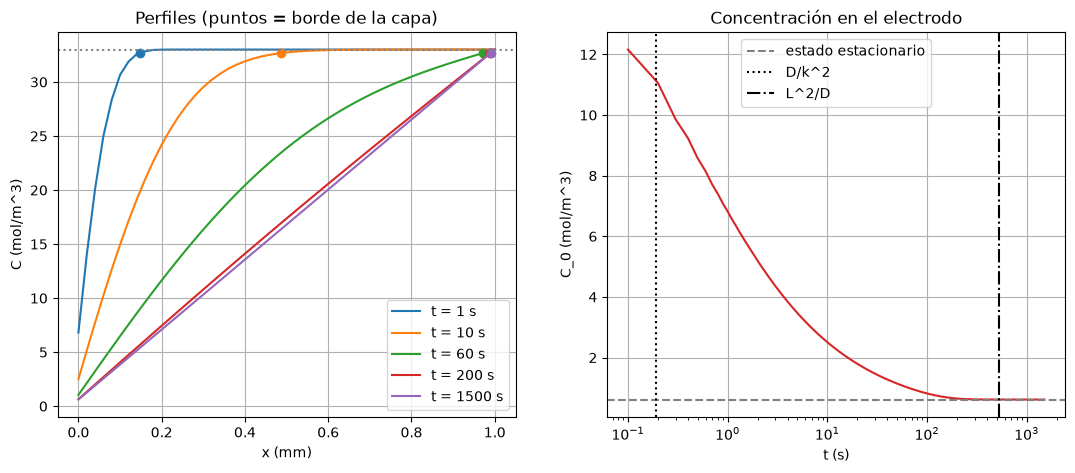

D/k^2 = 0.19 s   |   L^2/D = 526 s
C_0 estacionario (teoría)    = 0.615 mol/m^3
C_0 al final (simulación)    = 0.615 mol/m^3


In [30]:
plt.figure(figsize=(13, 5))

# 1: perfiles
plt.subplot(1, 2, 1)
x_mm = []
for i in range(N + 1):
    x_mm.append(x[i] * 1e3)

colores = ["C0", "C1", "C2", "C3", "C4"]
tiempos = [1, 10, 60, 200, 1500]
for q in range(len(tiempos)):
    tiempo = tiempos[q]
    m = int(round(tiempo / dt))
    perfil = lista_perfiles[m]
    delta = grosor_capa(perfil)
    plt.plot(x_mm, perfil, color=colores[q], label=f"t = {tiempo} s")
    plt.plot(delta * 1e3, 0.99 * C_bulk, "o", color=colores[q])

plt.axhline(C_bulk, color="gray", linestyle=":")
plt.xlabel("x (mm)")
plt.ylabel("C (mol/m^3)")
plt.title("Perfiles (puntos = borde de la capa)")
plt.legend()
plt.grid(True)

# 2: concentración en el electrodo contra el tiempo
plt.subplot(1, 2, 2)
tiempos_sin_cero = []
C0_sin_cero = []
for m in range(1, len(lista_tiempos)):
    tiempos_sin_cero.append(lista_tiempos[m])
    C0_sin_cero.append(lista_C0[m])

plt.plot(tiempos_sin_cero, C0_sin_cero, color="C3")
plt.xscale("log")
plt.axhline(C0_estacionario, color="gray", linestyle="--", label="estado estacionario")
plt.axvline(t_reaccion, color="k", linestyle=":", label="D/k^2")
plt.axvline(t_difusion, color="k", linestyle="-.", label="L^2/D")
plt.xlabel("t (s)")
plt.ylabel("C_0 (mol/m^3)")
plt.title("Concentración en el electrodo")
plt.legend()
plt.grid(True)

plt.show()

print(f"D/k^2 = {t_reaccion:.2f} s   |   L^2/D = {t_difusion:.0f} s")
print(f"C_0 estacionario (teoría)    = {C0_estacionario:.3f} mol/m^3")
print(f"C_0 al final (simulación)    = {lista_C0[-1]:.3f} mol/m^3")